# Bab 9 – Text Processing and Multiclass Classification

## Ringkasan Bab
Model machine learning hanya menerima angka, jadi teks harus diubah menjadi vektor numerik lebih dulu. Bab ini membahas
pemrosesan teks, **vektorisasi** (Bag-of-Words dan TF-IDF), ekstraksi fitur, pembuatan **classifier teks**, strategi
**klasifikasi multikelas** (OvR dan OvO), serta cara mengevaluasi model teks. Dataset teks dibuat sendiri secara sintetis
agar notebook bisa dijalankan tanpa unduhan.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, re
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer, HashingVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.multiclass import OneVsRestClassifier, OneVsOneClassifier
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, f1_score
rng = np.random.default_rng(0)

# Korpus sintetis: 4 topik, tiap dokumen campuran kata topik, kata umum, dan sedikit kata dari topik lain (noise)
topics = {
 "olahraga":  "team match player goal coach league score season stadium tournament win training".split(),
 "teknologi": "software computer data network server code algorithm device startup cloud update digital".split(),
 "kesehatan": "doctor patient hospital disease vaccine therapy symptom diet nutrition medicine health treatment".split(),
 "ekonomi":   "market inflation bank investor budget trade stock price growth currency tax profit".split()}
common = "the a of and to in is was for on with this that new people year said about".split()
docs, labels = [], []
for lab, words in topics.items():
    others = [w for k, v in topics.items() if k != lab for w in v]
    for _ in range(150):
        toks = list(rng.choice(words, 3)) + list(rng.choice(others, 3)) + list(rng.choice(common, 12))
        rng.shuffle(toks); docs.append(" ".join(toks)); labels.append(lab)
df = pd.DataFrame({"text": docs, "label": labels}).sample(frac=1, random_state=1).reset_index(drop=True)
df.head()

,text,label
0,in hospital in doctor with said said people te...,kesehatan
1,was and this nutrition training is is symptom ...,kesehatan
2,in the vaccine year score year about said budg...,ekonomi
3,growth training new people this a market year ...,ekonomi
4,said code doctor about said on and to the comp...,teknologi


## 1. Pengantar Pemrosesan Teks
Tahapan umum: **tokenisasi** (memecah teks jadi kata), **lowercase**, **membuang stop words** (kata umum seperti "the"),
**normalisasi** (stemming/lemmatization), lalu **vektorisasi**. Di scikit-learn, sebagian besar langkah ini sudah ada dalam
parameter vectorizer (`lowercase`, `stop_words`, `ngram_range`, `min_df`, `max_df`).

In [2]:
def clean(t): return re.sub(r"[^a-z\s]", " ", t.lower())
print(clean("Hello, World! 2026 is NEW."))
print(df.label.value_counts())

hello  world       is new 
label
kesehatan    150
ekonomi      150
teknologi    150
olahraga     150
Name: count, dtype: int64


## 2. Teknik Vektorisasi Teks
* **Bag-of-Words (`CountVectorizer`)**: tiap dokumen menjadi vektor frekuensi kata. Urutan kata diabaikan.
* **TF-IDF (`TfidfVectorizer`)**: TF-IDF(t, d) = TF(t, d) × IDF(t), dengan IDF(t) = log(N / df(t)) (versi sklearn diberi penyesuaian smoothing).
  Kata yang sering muncul di satu dokumen tetapi jarang di dokumen lain mendapat bobot tinggi, sedangkan kata umum bobotnya kecil.
* **N-gram**: `ngram_range=(1, 2)` menambahkan pasangan kata sehingga sebagian konteks tertangkap.
* **HashingVectorizer**: memakai fungsi hash sehingga tidak perlu menyimpan kamus kata, cocok untuk data besar.

In [3]:
mini = ["the team won the match", "the doctor treats the patient", "the team and the doctor"]
cv = CountVectorizer(); B = cv.fit_transform(mini)
print(pd.DataFrame(B.toarray(), columns=cv.get_feature_names_out()))
tf = TfidfVectorizer(); T = tf.fit_transform(mini)
print(pd.DataFrame(T.toarray().round(2), columns=tf.get_feature_names_out()))
print("Bentuk matriks sparse korpus:", TfidfVectorizer().fit_transform(df.text).shape)

   and  doctor  match  patient  team  the  treats  won
0    0       0      1        0     1    2       0    1
1    0       1      0        1     0    2       1    0
2    1       1      0        0     1    2       0    0
    and  doctor  match  patient  team   the  treats  won
0  0.00    0.00    0.5      0.0  0.38  0.59     0.0  0.5
1  0.00    0.38    0.0      0.5  0.00  0.59     0.5  0.0
2  0.53    0.40    0.0      0.0  0.40  0.63     0.0  0.0
Bentuk matriks sparse korpus: (600, 65)


## 3. Ekstraksi Fitur dari Teks
Hasil vektorisasi berupa **matriks sparse** (sebagian besar elemennya nol), sehingga hemat memori. Kita dapat melihat
kata dengan bobot TF-IDF tertinggi untuk memahami fitur yang dipakai model.

In [4]:
tfv = TfidfVectorizer(stop_words="english", min_df=2); Xt = tfv.fit_transform(df.text)
terms = np.array(tfv.get_feature_names_out())
for lab in topics:
    m = np.asarray(Xt[(df.label == lab).values].mean(axis=0)).ravel()
    print(f"{lab:10s}:", ", ".join(terms[m.argsort()[::-1][:6]]))

olahraga  : said, people, new, year, win, team
teknologi : people, year, said, new, server, network
kesehatan : year, new, said, nutrition, people, hospital
ekonomi   : new, people, year, said, market, currency


## 4. Membangun Model Klasifikasi Teks
Vectorizer dan classifier digabung dalam satu `Pipeline` agar tidak ada kebocoran dan mudah disimpan.
Kombinasi klasik: TF-IDF + **Multinomial Naive Bayes**, **Logistic Regression**, atau **LinearSVC**.

In [5]:
Xtr, Xte, ytr, yte = train_test_split(df.text, df.label, test_size=.25, stratify=df.label, random_state=0)
pipes = {"NB": make_pipeline(CountVectorizer(stop_words="english"), MultinomialNB()),
         "TFIDF+LogReg": make_pipeline(TfidfVectorizer(stop_words="english"), LogisticRegression(max_iter=1000)),
         "TFIDF+LinearSVC": make_pipeline(TfidfVectorizer(stop_words="english", ngram_range=(1, 2)), LinearSVC())}
for n, p in pipes.items():
    print(f"{n:16s} CV akurasi = {cross_val_score(p, Xtr, ytr, cv=5).mean():.3f}")

NB               CV akurasi = 0.840
TFIDF+LogReg     CV akurasi = 0.920


TFIDF+LinearSVC  CV akurasi = 0.798


## 5. Strategi Klasifikasi Multikelas
* **One-vs-Rest (OvR):** K model biner ("kelas k vs sisanya"). Hemat, dan default untuk `LinearSVC`.
* **One-vs-One (OvO):** K(K−1)/2 model, satu untuk tiap pasangan kelas, lalu voting. Cocok untuk model yang lambat pada data besar (misal SVM kernel).
* **Multinomial/softmax:** satu model langsung untuk semua kelas (Logistic Regression, Naive Bayes).

In [6]:
for n, clf in [("OvR", OneVsRestClassifier(LinearSVC())), ("OvO", OneVsOneClassifier(LinearSVC()))]:
    p = make_pipeline(TfidfVectorizer(stop_words="english"), clf).fit(Xtr, ytr)
    print(f"{n}: jumlah model = {len(p[-1].estimators_)} | F1 macro uji = {f1_score(yte, p.predict(Xte), average='macro'):.3f}")

OvR: jumlah model = 4 | F1 macro uji = 0.913


OvO: jumlah model = 6 | F1 macro uji = 0.899


## 6. Mengevaluasi Model Teks
Gunakan **F1 macro** (semua kelas dianggap sama penting), **confusion matrix**, dan periksa kata yang paling berpengaruh pada tiap kelas.

              precision    recall  f1-score   support

     ekonomi       0.95      0.95      0.95        38
   kesehatan       0.94      0.84      0.89        38
    olahraga       0.82      0.86      0.84        37
   teknologi       0.92      0.97      0.95        37

    accuracy                           0.91       150
   macro avg       0.91      0.91      0.91       150
weighted avg       0.91      0.91      0.91       150



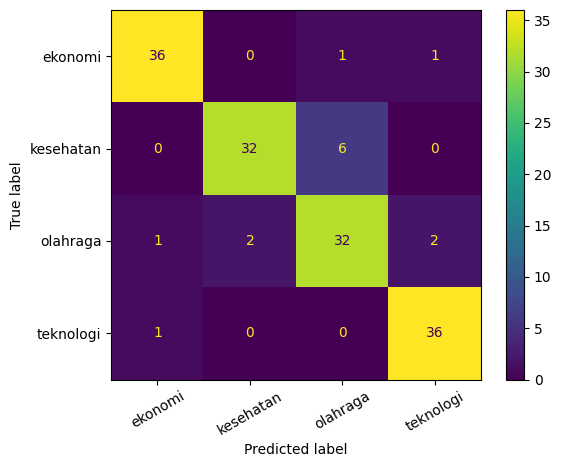

ekonomi   : currency, bank, market, growth, investor
kesehatan : disease, health, nutrition, hospital, treatment
olahraga  : tournament, win, goal, league, score
teknologi : server, device, startup, network, cloud


In [7]:
best = pipes["TFIDF+LogReg"].fit(Xtr, ytr); pred = best.predict(Xte)
print(classification_report(yte, pred)); ConfusionMatrixDisplay.from_predictions(yte, pred, xticks_rotation=30); plt.show()
vec, lr = best[0], best[-1]; names = np.array(vec.get_feature_names_out())
for i, c in enumerate(lr.classes_): print(f"{c:10s}:", ", ".join(names[lr.coef_[i].argsort()[::-1][:5]]))

## 7. Latihan Praktik

### Latihan 1 – Preprocessing dan Vektorisasi Teks
Bandingkan pengaruh `ngram_range`, `min_df`, dan `sublinear_tf` terhadap akurasi.

In [8]:
gs = GridSearchCV(Pipeline([("tfidf", TfidfVectorizer(stop_words="english")), ("clf", LogisticRegression(max_iter=1000))]),
    {"tfidf__ngram_range": [(1, 1), (1, 2)], "tfidf__min_df": [1, 3], "tfidf__sublinear_tf": [True, False], "clf__C": [0.1, 1, 10]},
    cv=3, scoring="f1_macro", n_jobs=-1).fit(Xtr, ytr)
print("Terbaik:", gs.best_params_, "| F1 CV:", round(gs.best_score_, 3))

Terbaik: {'clf__C': 10, 'tfidf__min_df': 1, 'tfidf__ngram_range': (1, 1), 'tfidf__sublinear_tf': False} | F1 CV: 0.911


### Latihan 2 – Membangun dan Mengevaluasi Classifier Teks
Prediksi topik untuk kalimat baru dengan model terbaik.

In [9]:
new = ["the investor worried about inflation and the bank", "the coach praised the player after the goal", "a new vaccine reduces disease symptoms"]
for t, p, pr in zip(new, gs.predict(new), gs.predict_proba(new).max(1)): print(f"{p:10s} ({pr:.2f}) <- {t}")
print("F1 macro uji:", round(f1_score(yte, gs.predict(Xte), average='macro'), 3))

ekonomi    (1.00) <- the investor worried about inflation and the bank
olahraga   (1.00) <- the coach praised the player after the goal
kesehatan  (1.00) <- a new vaccine reduces disease symptoms
F1 macro uji: 0.913


**Kesimpulan:** TF-IDF dengan model linear adalah baseline yang kuat untuk klasifikasi teks. Pipeline menjaga seluruh alur tetap rapi.
Catatan: korpus di sini sintetis sehingga hasilnya mudah; pada data nyata (berita, ulasan) akurasi biasanya lebih rendah.